## Multi-AI Agent Systems

Single AI Agent = One AI agent performs the tasks.

Multi-AI Agent = Multiple specialized AI agents work together to complete a task.

> What is a Multi-AI Agent System?

Imagine you are planning a trip to Goa.

You ask an AI assistant:
"Plan my Goa trip for 3 days, including flights, hotels, tourist places, and the total budget."

Instead of one AI agent doing everything, we can create multiple specialized agents.
- Flight Agent: Searches for flights.
- Hotel Agent: Finds suitable hotels.
- Travel Agent: Recommends tourist attractions.
- Budget Agent: Calculates the total estimated cost.
Each agent is responsible for a particular task.

#### Types of Multi-Agent Systems

There isn't one universal classification. In LangGraph, the following are common architectural patterns.

1. Supervisor Architecture : One supervisor agent manages multiple worker agents.


2. Handoff / Swarm Architecture : Agents transfer control directly to other agents.


3. Hierarchical Architecture : Multiple levels of supervisors manage groups of agents.


4. Sequential Architecture : Agents execute one after another in a defined order.


5. Parallel Architecture : Multiple agents execute independently, and their outputs are combined.

## SImple Multi AI Agent Architecture

In [4]:
import os
from typing import TypedDict,Annotated,List,Literal
from langchain_core.messages import BaseMessage,AIMessage,HumanMessage,SystemMessage
from langchain_groq import ChatGroq
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph.graph import START,StateGraph,END,MessagesState
from langgraph.prebuilt import create_react_agent,ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [5]:
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
os.environ['GROQ_API_KEY']= os.getenv('GROQ_API_KEY')
os.environ['LANGSMITH_API_KEY'] = os.getenv('LANGSMITH_API_KEY')


In [7]:
class AgentState(MessagesState):
    # Which agent should go next
    next_agent:str 

In [8]:
from langchain_core.tools import tool
@tool 
def search_web(query:str) -> str:
    """Search the web for information"""
    # Use Tavily for web Search
    search = TavilySearchResults(max_results=3)
    results = search.invoke(query)
    return str(results)


def write_summary(content:str) -> str:
    """Write a summary of the provided content"""
    #Simple Summary Generation
    summary = f"Summary of findings:/n/n{content[:500]}"
    return summary

In [9]:
from langchain.chat_models import init_chat_model
llm = init_chat_model(
    model="groq:openai/gpt-oss-120b"
)

In [11]:
# llm_with_tools = llm.bind_tools([write_summary,search_web])

In [13]:
def researcher_agent(state:AgentState):
    """Researcher agent that searches for information"""

    messages = state['messages']

    # Add System Prompt for context
    system_msg = SystemMessage(content="You are a research assistant.Use the search_web tool to find the information about the user's request")


    #call LLM with tools
    reseacher_llm = llm.bind_tools([search_web])
    response = reseacher_llm.invoke([system_msg] + messages)

    return {
        "messsages":[response],
        "next_agent":"writer"
    }

In [12]:
def writer_agent(state:AgentState):
    """Writer agent that creates for summary"""

    messages = state['messages']

    # Add System Prompt for context
    system_msg = SystemMessage(content="You are a technical writer.Review the conversation and create a clear ,concise summary of the findings")


    #call LLM with tools
    response = llm.invoke([system_msg] + messages)

    return {
        "messsages":[response],
        "next_agent":"end"
    }

In [14]:
def execute_tools (state: AgentState):

    """Execute any pending tool calls"""
    messages = state["messages"]
    last_message = messages [-1]

    #Check if there are tool calls to execute
    if hasattr(last_message, "tool_calls") and last_message.tool_calls:
        #Create tool node and execute
        tool_node = ToolNode ([search_web, write_summary])
        response = tool_node.invoke(state)
        return response
        #No tools to execute
    return state

In [15]:
workflow = StateGraph(MessagesState)

workflow.add_node("researcher",researcher_agent)
workflow.add_node("writer",writer_agent)

workflow.add_edge(START,"researcher")
workflow.add_edge("researcher",'writer')
workflow.add_edge("writer",END)

final_workflow = workflow.compile()

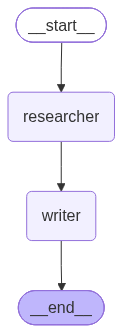

In [16]:
from IPython.display import Image,display
display(Image(final_workflow.get_graph().draw_mermaid_png()))

### Type 1: Supervisor Multi-Agent Architecture
Imagine a company with a manager and three employees.

The manager decides which employee should perform a particular task.

Similarly, in a Supervisor architecture, one agent coordinates multiple specialized agents.

### Type 2: Handoff / Swarm Architecture
In this architecture, agents communicate directly and transfer control between themselves.

There is no requirement for one central supervisor to coordinate every step

## Type 3: Hierarchical Multi-Agent Architecture
Hierarchical means multiple levels of management.

Imagine:
- CEO
- Department managers
- Employees

Similarly, a hierarchical multi-agent system can have a main supervisor, sub-supervisors, and worker agents.

## Type 4: Sequential Multi-Agent Architecture
Sequential means agents execute one after another .Each agent uses the output of the previous agent.

Best for: Document generation, research pipelines, and content creation.

## Type 5: Parallel Multi-Agent Architecture
Parallel means multiple agents can work independently at the same time.

Example: Product Comparison

User asks: "Compare Samsung, Apple, and OnePlus smartphones."

All three research agents can work independently. Once their results are available, the comparison agent combines them.

Best for: Independent research, data collection, and comparison tasks.